# Repaso Parcial Práctico 03 — DDYA 2025-2
### Solución paso a paso del Pre-Parcial

| # | Problema | Tema | Estructura / Algoritmo clave | Complejidad |
|---|----------|------|------------------------------|-------------|
| 1 | A - Cola de impresión 3D | Prioridades | **Heap (cola de prioridad)** con desempate por orden de llegada | $O(q \log q)$ |
| 2 | B - Préstamos del laboratorio | Tablas hash | **Diccionario** + contador de tipos activos | $O(q)$ esperado |
| 3 | C - Red de sensores por zonas | Conectividad | **Union-Find (DSU)** con compresión de caminos y unión por tamaño | $O(q\,\alpha(n))$ |
| 4 | D - Cableado mínimo protoboard | Redes | **Árbol de expansión mínima** (Prim $O(n^2)$ en grafo completo) | $O(n^2)$ |
| 5 | E - Robot de mantenimiento | Redes | **Dijkstra** con heap | $O((n+m)\log m)$ |

**Cómo usar este notebook:**
1. Lee el enunciado resumido y **piensa la idea tú primero** antes de leer la solución.
2. Lee la *idea clave* → la *traza a mano* → el *código*.
3. Ejecuta la celda de pruebas: corre los 3 casos del PDF y dice ✅ o ❌.

Cada solución está escrita como una función `resolver(texto) -> str` para poder probarla dentro del notebook. Al final de cada problema está la **versión para entregar** (lee de `stdin`, escribe en `stdout`), que es la que pegas en el juez.


---
# 1. (6 pts) A — Cola de impresión 3D

**Enunciado resumido.** Llegan eventos:
- `AGREGA nombre p` → entra un trabajo con prioridad `p` (mayor = sale antes).
- `PROCESA` → sale e imprime el trabajo de **mayor prioridad**; si hay empate, el que **llegó antes**.

$q \le 200\,000$. Restricción: *no se puede reordenar todo en cada PROCESA* (o sea, nada de `sort` por cada evento → eso sería $O(q^2 \log q)$).

## Paso 1 — Reconocer el patrón
"Sacar siempre el mayor, mientras siguen llegando elementos" = **cola de prioridad** → se implementa con un **heap**.

- Insertar: $O(\log n)$
- Sacar el máximo: $O(\log n)$

## Paso 2 — Los dos detalles que te pueden hacer perder puntos

**(a) `heapq` de Python es un *min-heap*** (saca el **menor**). Para sacar la prioridad **mayor**, guardamos `-p`.

**(b) El desempate.** Python compara tuplas elemento por elemento. Si guardamos `(-p, orden_llegada, nombre)`:
- Primero compara `-p` → gana la prioridad más alta.
- Si empatan, compara `orden_llegada` → gana el que llegó antes (contador más pequeño).
- Como `orden_llegada` es único, **nunca** llega a comparar `nombre` (si comparara nombres, desempataría alfabéticamente, ¡que es incorrecto!).

> El PDF lo dice: *"el orden de llegada forma parte de la prioridad efectiva del trabajo"*. Eso es exactamente la tupla `(-p, orden)`.

## Paso 3 — Traza a mano del caso 1

| Evento | Heap (como `(-p, orden, nombre)`) | Imprime |
|---|---|---|
| AGREGA piezaA 4 | `(-4,0,A)` | |
| AGREGA piezaB 7 | `(-7,1,B) (-4,0,A)` | |
| AGREGA piezaC 7 | `(-7,1,B) (-7,2,C) (-4,0,A)` | |
| PROCESA | saca `(-7,1,B)` — empata con C en −7, gana orden 1 < 2 | **piezaB** |
| AGREGA piezaD 10 | `(-10,3,D) (-7,2,C) (-4,0,A)` | |
| PROCESA | saca `(-10,3,D)` | **piezaD** |
| PROCESA | saca `(-7,2,C)` | **piezaC** |
| AGREGA piezaE 5 | `(-5,4,E) (-4,0,A)` | |
| PROCESA | saca `(-5,4,E)` | **piezaE** |

Salida: `piezaB, piezaD, piezaC, piezaE` ✔️

## Paso 4 — Complejidad
Cada evento hace a lo sumo un `push` o un `pop`: $O(\log q)$ → total **$O(q \log q)$**. Memoria $O(q)$.

## Codigo Interactivo:

In [ ]:
import heapq

def solicitar_q():
    q = int(input("Ingrese el numero de eventos a agregar: "))  
    while q < 1:
        print("El numero de eventos debe ser mayor o igual a 1")
        q = int(input("Ingrese el numero de eventos a agregar: "))
    return q

def llenar_heap(q, cola_prioridad, contador_llegada):
    for rep in range(q):
        producto = input("Ingrese el nombre del producto: ")
        while len(producto) < 1 or len(producto) > 30:
            print("El nombre del producto debe tener al menos 1 caracter y no más de 30")
            producto = input("Ingrese el nombre del producto: ")
        
        prioridad = int(input("Ingrese la prioridad del producto 1-10^9: "))
        while prioridad < 1 or prioridad > 10**9:
            print("La prioridad debe ser un número entre 1 y 10^9")
            prioridad = int(input("Ingrese la prioridad del producto 1-10^9: "))
        
        # heapq es un Min-Heap: usamos -prioridad para que el mayor salga primero,
        # y contador_llegada positivo para desempatar por orden de llegada.
        heapq.heappush(cola_prioridad, (-prioridad, contador_llegada, producto))
        contador_llegada += 1
        
    return contador_llegada

def procesar(cola_prioridad):
    # heappop extrae y reordena automáticamente en O(log n)
    prio_neg, _, prod_max = heapq.heappop(cola_prioridad)
    print(f"Procesado: {prod_max} (Prioridad: {-prio_neg})")

def main():
    cola_prioridad = []
    contador_llegada = 0

    menu = True
    while menu:
        print("\n1. Agregar productos")
        print("2. Procesar")
        print("3. Imprimir productos en cola")
        print("4. Salir")

        opcion = int(input("Seleccione una opción: "))
        if opcion == 1:
            q = solicitar_q()
            contador_llegada = llenar_heap(q, cola_prioridad, contador_llegada)
            print("Productos agregados exitosamente.")
        elif opcion == 2:
            if len(cola_prioridad) >= 1:
                print("Procesando producto de mayor prioridad...")
                procesar(cola_prioridad)
            else:
                print("No hay productos para procesar. Por favor, agregue productos primero.")
        elif opcion == 3:
            if len(cola_prioridad) >= 1:
                print("Productos en cola (de mayor a menor prioridad):")
                for prio_neg, _, prod in sorted(cola_prioridad):
                    print(f"{prod} (Prioridad: {-prio_neg})")
            else:
                print("No hay productos en la cola.")
        elif opcion == 4:
            print("Saliendo del programa.")
            menu = False
main()  

## Codigo para Juez

### Versión para entregar (stdin → stdout)
Leer todo de una con `sys.stdin.read().splitlines()` es mucho más rápido que `input()` cuando hay 200 000 líneas.

In [ ]:
import sys
import heapq

def main():
    # Lee toda la entrada estándar de golpe para evitar demoras con hasta 200,000 líneas
    datos = sys.stdin.read().splitlines()
    if not datos:
        return

    q = int(datos[0])
    cola_prioridad = []
    contador_llegada = 0
    salida = []

    for rep in range(1, q + 1):
        linea = datos[rep].split()
        instruccion = linea[0]

        if instruccion == "AGREGA":
            nombre = linea[1]
            prioridad = int(linea[2])
            # (-prioridad) para simular Max-Heap y (contador_llegada) para desempatar
            heapq.heappush(cola_prioridad, (-prioridad, contador_llegada, nombre))
            contador_llegada += 1
        elif instruccion == "PROCESA":
            _, _, nombre = heapq.heappop(cola_prioridad)
            salida.append(nombre)

    # Imprime todos los resultados juntos separados por salto de línea
    if salida:
        sys.stdout.write("\n".join(salida) + "\n")
main()

---
# 2. (6 pts) B — Préstamos del laboratorio

**Enunciado resumido.** Operaciones:
- `PRESTA codigo` → una unidad más prestada de ese modelo.
- `DEVUELVE codigo` → una unidad menos (siempre hay al menos una prestada).
- `CONSULTA codigo` → imprimir cuántas unidades de ese modelo están prestadas ahora (0 si nunca se vio).
- `TIPOS_ACTIVOS` → imprimir cuántos modelos tienen **≥ 1** préstamo activo.

Restricción: no recorrer todos los préstamos en cada consulta.

## Paso 1 — Reconocer el patrón
"Localizar un código en tiempo esperado constante" = **tabla hash** → en Python, `dict`.

`prestados[codigo] = unidades prestadas actualmente`

## Paso 2 — El truco: `TIPOS_ACTIVOS` en $O(1)$
La solución ingenua sería contar cuántos valores del diccionario son > 0 → eso recorre todo ($O(\text{modelos})$) **en cada consulta** → $O(q^2)$ en el peor caso. ❌

En vez de eso, mantenemos un **contador `activos`** que se actualiza solo en las *transiciones*:
- `PRESTA`: si el modelo pasa de **0 → 1**, `activos += 1`.
- `DEVUELVE`: si el modelo pasa de **1 → 0**, `activos -= 1`.

Así cada operación es $O(1)$ esperado. Esta idea de "mantener un agregado actualizado incrementalmente" sale MUCHO en parciales.

## Paso 3 — Traza a mano del caso 1

| Operación | `prestados` | `activos` | Imprime |
|---|---|---|---|
| PRESTA camara | {camara:1} | 1 (0→1) | |
| PRESTA camara | {camara:2} | 1 | |
| PRESTA microfono | {camara:2, microfono:1} | 2 (0→1) | |
| CONSULTA camara | | | **2** |
| DEVUELVE camara | {camara:1, microfono:1} | 2 | |
| TIPOS_ACTIVOS | | | **2** |
| DEVUELVE camara | {camara:0, microfono:1} | 1 (1→0) | |
| CONSULTA camara | | | **0** |
| TIPOS_ACTIVOS | | | **1** |
| CONSULTA microfono | | | **1** |

Salida: `2 2 0 1 1` ✔️

**Caso borde (caso 2):** `CONSULTA dron` antes de que exista → usar `prestados.get(codigo, 0)` para imprimir `0` sin error.

## Paso 4 — Complejidad
Cada operación $O(1)$ esperado (hash) → total **$O(q)$** esperado (por la longitud de las cadenas, estrictamente $O(\sum |codigo|)$).


## Codigo interactivo

In [ ]:
def solicitar_codigo():
    codigo = input("Ingrese el código del equipo (1-20 letras minúsculas): ")
    while not (1 <= len(codigo) <= 20 and codigo.isalpha() and codigo.islower()): #is alpha valida que solo sean letras y no hayan espacios ni cadenas vacias ´camara web´ 
        print("Error: El código debe tener entre 1 y 20 letras minúsculas, no debe tener espacios.")
        codigo = input("Ingrese el código del equipo: ")
    return codigo

def prestar(prestamos, activos, codigo):
    cantidad_actual = prestamos.get(codigo, 0)
    if cantidad_actual == 0:
        activos += 1  # Pasa a tener al menos un préstamo activo
    prestamos[codigo] = cantidad_actual + 1
    print(f"Préstamo registrado. Unidades actuales de '{codigo}': {prestamos[codigo]}")
    return activos

def devolver(prestamos, activos, codigo):
    cantidad_actual = prestamos.get(codigo, 0)
    if cantidad_actual == 0:
        print(f"Error: No hay unidades prestadas de '{codigo}' para devolver.")
        return activos
    
    prestamos[codigo] = cantidad_actual - 1
    if prestamos[codigo] == 0:
        activos -= 1  # Deja de contar como tipo activo
        print(f"Devolución registrada. Ya no quedan unidades de '{codigo}' prestadas.")
    else:
        print(f"Devolución registrada. Unidades restantes de '{codigo}': {prestamos[codigo]}")
    return activos

def main():
    prestamos = {}  # Tabla hash: {codigo: cantidad_prestada}
    activos = 0     # Contador de tipos de equipo con >= 1 préstamo activo

    menu = True
    while menu:
        print("\n--- PRÉSTAMOS DEL LABORATORIO ---")
        print("1. PRESTA equipo")
        print("2. DEVUELVE equipo")
        print("3. CONSULTA equipo")
        print("4. TIPOS_ACTIVOS")
        print("5. Salir")

        opcion = input("Seleccione una opción: ")

        if opcion == "1":
            cod = solicitar_codigo()
            activos = prestar(prestamos, activos, cod)
        elif opcion == "2":
            cod = solicitar_codigo()
            activos = devolver(prestamos, activos, cod)
        elif opcion == "3":
            cod = solicitar_codigo()
            print(f"Unidades prestadas de '{cod}': {prestamos.get(cod, 0)}")
        elif opcion == "4":
            print(f"Tipos de equipo activos actualmente: {activos}")
        elif opcion == "5":
            print("Saliendo del sistema.")
            menu = False
        else:
            print("Opción no válida.")
main()

## Codigo para Juez

In [ ]:
import sys

def main():
    datos = sys.stdin.read().splitlines()
    if not datos:
        return

    q = int(datos[0])
    prestamos = {}
    activos = 0
    salida = []

    for rep in range(1, q + 1):
        linea = datos[rep].split()
        operacion = linea[0]

        if operacion == "PRESTA":
            codigo = linea[1]
            actual = prestamos.get(codigo, 0)
            if actual == 0:
                activos += 1
            prestamos[codigo] = actual + 1

        elif operacion == "DEVUELVE":
            codigo = linea[1]
            if prestamos.get(codigo, 0) > 0:
                prestamos[codigo] -= 1
                if prestamos[codigo] == 0:
                    activos -= 1

        elif operacion == "CONSULTA":
            codigo = linea[1]
            # Si el código nunca ha sido prestado o ya se devolvió todo, devuelve 0
            salida.append(str(prestamos.get(codigo, 0)))

        elif operacion == "TIPOS_ACTIVOS":
            salida.append(str(activos))

    if salida:
        sys.stdout.write("\n".join(salida) + "\n")

main()

---
# 3. (6 pts) C — Red de sensores por zonas

**Enunciado resumido.** $n$ sensores, inicialmente cada uno solo. Operaciones:
- `CONECTA a b` → une **las redes completas** de `a` y `b`.
- `MISMA_RED a b` → `SI` / `NO`.
- `TAMANO a` → número de sensores en la red de `a`.

## Paso 1 — Reconocer el patrón
Uniones de conjuntos + preguntar "¿están en el mismo conjunto?" + nunca se separan = **Union-Find / Disjoint Set Union (DSU)**. El mismo PDF lo sugiere.

## Paso 2 — Cómo funciona el DSU
Cada red es un **árbol**; la raíz es el "representante" de la red.
- `padre[x]`: el padre de `x` en su árbol (la raíz es su propio padre).
- `tam[raiz]`: tamaño de la red (solo es válido en las raíces).

**`find(x)`** → sube por los padres hasta la raíz.
- **Compresión de caminos:** al terminar, hacemos que todos los nodos del camino apunten directo a la raíz → los siguientes `find` son casi instantáneos.

**`union(a, b)`**:
1. `ra = find(a)`, `rb = find(b)`.
2. Si `ra == rb` → ya están en la misma red, **no se hace nada** (el enunciado lo exige: "no cambia la organización"; si no lo controlas, ¡sumarías el tamaño dos veces!).
3. **Unión por tamaño:** colgamos la raíz del árbol **pequeño** debajo de la del **grande** y `tam[grande] += tam[pequeño]`.

**`MISMA_RED a b`** → `find(a) == find(b)`.
**`TAMANO a`** → `tam[find(a)]`.

Con ambas optimizaciones cada operación cuesta $O(\alpha(n))$ amortizado (la inversa de Ackermann, que en la práctica es ≤ 4 → prácticamente constante).

## Paso 3 — Traza a mano del caso 1 ($n=7$)

| Operación | Redes | Imprime |
|---|---|---|
| inicio | {1} {2} {3} {4} {5} {6} {7} | |
| MISMA_RED 1 2 | find(1)=1 ≠ find(2)=2 | **NO** |
| CONECTA 1 2 | {1,2} {3} {4} {5} {6} {7} | |
| CONECTA 2 3 | {1,2,3} ... | |
| TAMANO 1 | tam[find(1)] = 3 | **3** |
| CONECTA 4 5 | {1,2,3} {4,5} {6} {7} | |
| MISMA_RED 3 5 | distintas raíces | **NO** |
| CONECTA 3 5 | {1,2,3,4,5} {6} {7} | |
| MISMA_RED 4 1 | misma raíz | **SI** |
| TAMANO 5 | 5 | **5** |

✔️ `NO 3 NO SI 5`

## Paso 4 — Detalle de implementación en Python
Un `find` **recursivo** puede romper el límite de recursión de Python (1000) si el árbol se pone profundo. Lo escribimos **iterativo** (dos pasadas: subir a la raíz, luego re-apuntar el camino).

## Codigo interactivo



In [ ]:
def find(padre, x):
    # Compresión de caminos: hace que todos los nodos apunten directo al líder raíz
    if padre[x] != x:
        padre[x] = find(padre, padre[x])
    return padre[x]

def union(padre, tamano, a, b):
    raiz_a = find(padre, a)
    raiz_b = find(padre, b)

    if raiz_a == raiz_b:
        print(f"Los sensores {a} y {b} ya pertenecían a la misma red.")
        return

    # Unión por tamaño: pegamos el árbol más pequeño debajo del más grande
    if tamano[raiz_a] < tamano[raiz_b]:
        raiz_a, raiz_b = raiz_b, raiz_a

    padre[raiz_b] = raiz_a
    tamano[raiz_a] += tamano[raiz_b]
    print(f"Redes conectadas. Nuevo tamaño de la red: {tamano[raiz_a]}")

def main():
    n = int(input("Ingrese el número total de sensores (n): "))
    while n < 1:
        n = int(input("n debe ser al menos 1. Ingrese n: "))

    # Inicialización: índices de 1 a n
    padre = list(range(n + 1))
    tamano = [1] * (n + 1)

    menu = True
    while menu:
        print("\n--- RED DE SENSORES ---")
        print("1. CONECTA a b")
        print("2. MISMA_RED a b")
        print("3. TAMANO a")
        print("4. Salir")

        opcion = input("Seleccione una opción: ")

        if opcion == "1":
            a = int(input("Sensor a: "))
            b = int(input("Sensor b: "))
            if 1 <= a <= n and 1 <= b <= n:
                union(padre, tamano, a, b)
            else:
                print(f"Error: Los sensores deben estar entre 1 y {n}.")

        elif opcion == "2":
            a = int(input("Sensor a: "))
            b = int(input("Sensor b: "))
            if 1 <= a <= n and 1 <= b <= n:
                if find(padre, a) == find(padre, b):
                    print("SI")
                else:
                    print("NO")
            else:
                print(f"Error: Los sensores deben estar entre 1 y {n}.")

        elif opcion == "3":
            a = int(input("Sensor a: "))
            if 1 <= a <= n:
                raiz = find(padre, a)
                print(f"Tamaño de la red del sensor {a}: {tamano[raiz]}")
            else:
                print(f"Error: El sensor debe estar entre 1 y {n}.")

        elif opcion == "4":
            print("Saliendo...")
            menu = False
        else:
            print("Opción inválida.")
main()

### Codigo Juez

In [ ]:
import sys

def find(padre, x):
    # Encontrar la raíz de forma iterativa
    raiz = x
    while padre[raiz] != raiz:
        raiz = padre[raiz]
    
    # Compresión de caminos: apuntar cada nodo visitado directamente a la raíz
    while padre[x] != raiz:
        siguiente = padre[x]
        padre[x] = raiz
        x = siguiente
    return raiz

def union(padre, tamano, a, b):
    raiz_a = find(padre, a)
    raiz_b = find(padre, b)

    if raiz_a != raiz_b:
        # Unión por tamaño: el más pequeño se une al más grande
        if tamano[raiz_a] < tamano[raiz_b]:
            raiz_a, raiz_b = raiz_b, raiz_a
        padre[raiz_b] = raiz_a
        tamano[raiz_a] += tamano[raiz_b]

def main():
    datos = sys.stdin.read().splitlines()
    if not datos:
        return

    primera_linea = datos[0].split()
    n = int(primera_linea[0])
    q = int(primera_linea[1])

    padre = list(range(n + 1))
    tamano = [1] * (n + 1)
    salida = []

    for rep in range(1, q + 1):
        linea = datos[rep].split()
        op = linea[0]

        if op == "CONECTA":
            a = int(linea[1])
            b = int(linea[2])
            union(padre, tamano, a, b)

        elif op == "MISMA_RED":
            a = int(linea[1])
            b = int(linea[2])
            if find(padre, a) == find(padre, b):
                salida.append("SI")
            else:
                salida.append("NO")

        elif op == "TAMANO":
            a = int(linea[1])
            raiz = find(padre, a)
            salida.append(str(tamano[raiz]))

    if salida:
        print("\n".join(salida))
main()

---
# 4. (6 pts) D — Cableado mínimo en una protoboard

**Enunciado resumido.** $n \le 200$ componentes en posiciones $(f, c)$. Se puede poner cable entre **cualquier par**, con costo = distancia Manhattan $|f_1-f_2| + |c_1-c_2|$. Conectar todos con el menor costo total.

## Paso 1 — Reconocer el patrón
"Conectar todos los nodos, sin ciclos, minimizando la suma" = **Árbol de Expansión Mínima (MST)**.

- Nodos = componentes.
- Aristas = **todos los pares** → grafo **completo** con n-1 aristas.

⚠️ El enunciado advierte: **no basta con unir cada componente a su vecino más cercano** — eso puede dejar el grafo partido en varios grupos (ej. dos parejas cercanas entre sí pero lejos una de otra).

## Paso 2 — ¿Prim o Kruskal?
Ambos sirven. se decide utilzar kruskal

Distancias Manhattan relevantes: F–L = 1+6 = **7**, L–S = 3+3 = **6**, S–M = 2+3 = **5**, L–B = 6+3 = **9**, F–B = 7+3 = 10, S–B = 3+6 = 9.

| Paso | Se agrega | costo | `dist` de los que faltan después de actualizar | Total |
|---|---|---|---|---|
| 1 | F | 0 | L=7, S=13, B=10, M=18 | 0 |
| 2 | L (min=7) | 7 | S=6, B=9, M=11 | 7 |
| 3 | S (min=6) | 6 | B=9, M=5 | 13 |
| 4 | M (min=5) | 5 | B=9 | 18 |
| 5 | B (min=9) | 9 | — | **27** ✔️ |

## Complejidad
Complejidad del Problema 4

Construcción de aristas: $O(n^2)$ pares.

Ordenamiento de aristas (aristas.sort()): Como hay $E \approx \frac{n^2}{2}$ aristas, ordenarlas toma $O(E \log E) = O(n^2 \log(n^2)) = O(n^2 \log n)$.

Kruskal (Union-Find): $O(n^2 \cdot \alpha(n))$.

Complejidad total: $O(n^2 \log n)$. 

Para $n = 200$, esto son apenas unas $300\,000$ operaciones básicas, ejecutándose casi instantáneamente.


## Codigo Interactivo

In [ ]:
def find(padre, x):
    if padre[x] != x:
        padre[x] = find(padre, padre[x])
    return padre[x]

def union(padre, tamano, a, b):
    raiz_a = find(padre, a)
    raiz_b = find(padre, b)
    if raiz_a != raiz_b:
        if tamano[raiz_a] < tamano[raiz_b]:
            raiz_a, raiz_b = raiz_b, raiz_a
        padre[raiz_b] = raiz_a
        tamano[raiz_a] += tamano[raiz_b]
        return True
    return False

def calcular_mst_kruskal(componentes):
    n = len(componentes)
    if n <= 1:
        return 0, []

    aristas = []
    # 1. Calcular distancia Manhattan entre todos los pares
    for i in range(n):
        for j in range(i + 1, n):
            id1, f1, c1 = componentes[i]
            id2, f2, c2 = componentes[j]
            costo = abs(f1 - f2) + abs(c1 - c2)
            aristas.append((costo, i, j))

    # 2. Ordenar aristas por costo ascendente
    aristas.sort()

    # 3. Construir MST con Union-Find
    padre = list(range(n))
    tamano = [1] * n
    costo_total = 0
    cables_elegidos = []

    for costo, u, v in aristas:
        if union(padre, tamano, u, v):
            costo_total += costo
            cables_elegidos.append((componentes[u][0], componentes[v][0], costo))
            if len(cables_elegidos) == n - 1:
                break

    return costo_total, cables_elegidos

def main():
    componentes = []
    menu = True

    while menu:
        print("\n--- CABLEADO EN PROTOBOARD (KRUSKAL) ---")
        print("1. Agregar componente")
        print("2. Calcular cableado mínimo")
        print("3. Limpiar protoboard")
        print("4. Salir")

        opcion = input("Seleccione una opción: ")

        if opcion == "1":
            nombre = input("Identificador del componente (ej. F): ")
            fila = int(input("Fila: "))
            col = int(input("Columna: "))
            componentes.append((nombre, fila, col))
            print(f"Componente {nombre} agregado en ({fila}, {col}).")

        elif opcion == "2":
            if not componentes:
                print("No hay componentes en la protoboard.")
            else:
                total, cables = calcular_mst_kruskal(componentes)
                print(f"\nLongitud mínima total de cable: {total}")
                for u, v, costo in cables:
                    print(f"  Conectar {u} <-> {v} (costo: {costo})")

        elif opcion == "3":
            componentes.clear()
            print("Protoboard vacía.")

        elif opcion == "4":
            print("Saliendo...")
            menu = False
        else:
            print("Opción no válida.")
main()

## Codigo Juez

In [ ]:
import sys

def find(padre, x):
    raiz = x
    while padre[raiz] != raiz:
        raiz = padre[raiz]
    while padre[x] != raiz:
        siguiente = padre[x]
        padre[x] = raiz
        x = siguiente
    return raiz

def union(padre, tamano, a, b):
    raiz_a = find(padre, a)
    raiz_b = find(padre, b)
    if raiz_a != raiz_b:
        if tamano[raiz_a] < tamano[raiz_b]:
            raiz_a, raiz_b = raiz_b, raiz_a
        padre[raiz_b] = raiz_a
        tamano[raiz_a] += tamano[raiz_b]
        return True
    return False

def main():
    datos = sys.stdin.read().splitlines()
    if not datos:
        return

    n = int(datos[0].strip())
    if n <= 1:
        print(0)
        return

    puntos = []
    for i in range(1, n + 1):
        partes = datos[i].split()
        fila = int(partes[1])
        col = int(partes[2])
        puntos.append((fila, col))

    # Generar todas las aristas con distancia Manhattan
    aristas = []
    for i in range(n):
        f1, c1 = puntos[i]
        for j in range(i + 1, n):
            f2, c2 = puntos[j]
            costo = abs(f1 - f2) + abs(c1 - c2)
            aristas.append((costo, i, j))

    # Ordenar de menor a mayor longitud de cable
    aristas.sort()

    padre = list(range(n))
    tamano = [1] * n
    costo_total = 0
    aristas_usadas = 0

    for costo, u, v in aristas:
        if union(padre, tamano, u, v):
            costo_total += costo
            aristas_usadas += 1
            if aristas_usadas == n - 1:
                break

    print(costo_total)
main()

---
# 5. (7 pts) E — Robot de mantenimiento

**Enunciado resumido.** Grafo **no dirigido** con $n \le 10^5$ nodos y $m \le 2\cdot10^5$ aristas con peso $t \ge 1$ (puede haber varias aristas entre el mismo par). Hallar el menor tiempo de 1 a $n$, o `IMPOSIBLE`.

## Paso 1 — Reconocer el patrón
Camino más corto desde **un origen**, pesos **positivos** → **Dijkstra**.
- BFS no sirve (los pesos no son todos iguales).
- Bellman-Ford sería $O(nm) = 2\cdot10^{10}$ → demasiado lento.
- Enumerar rutas → exponencial (el enunciado lo prohíbe).

## Paso 2 — Algoritmo (Dijkstra con heap, "lazy")
1. Lista de adyacencia: por cada `u v t` agregar `(v,t)` a `adj[u]` **y** `(u,t)` a `adj[v]` (¡bidireccional!). Las aristas múltiples no molestan: Dijkstra se queda con la mejor.
2. `dist = [∞]*(n+1)`, `dist[1] = 0`, heap = `[(0, 1)]`.
3. Mientras el heap no esté vacío:
   - Sacar `(d, u)` con menor `d`.
   - Si `d > dist[u]` → es una entrada **vieja/obsoleta**, se ignora (`continue`). *Esto reemplaza al "decrease-key".*
   - Si `u == n` → podemos terminar temprano (ya es definitivo).
   - Para cada vecino `(v, t)`: si `d + t < dist[v]` → actualizar `dist[v]` y hacer `push((dist[v], v))`.
4. Si `dist[n]` sigue en ∞ → `IMPOSIBLE`.

**¿Por qué funciona?** Con pesos no negativos, cuando un nodo sale del heap con la menor distancia, ningún otro camino puede mejorarla después (cualquier desvío solo suma tiempo ≥ 0).

**Desbordamiento:** el costo máximo puede ser ~$10^5 \cdot 10^9 = 10^{14}$. En Python no hay problema; en **C++/Java usa `long long` / `long`**.

## Paso 3 — Traza del caso 1
Aristas: 1–2(8), 1–3(3), 3–2(2), 2–4(2), 3–5(8), 4–6(4), 5–6(1).

| Sale del heap | Relajaciones | dist [1..6] |
|---|---|---|
| (0, 1) | 2←8, 3←3 | 0, 8, 3, ∞, ∞, ∞ |
| (3, 3) | 2←3+2=**5** (mejora 8), 5←3+8=11 | 0, 5, 3, ∞, 11, ∞ |
| (5, 2) | 4←5+2=7 | 0, 5, 3, 7, 11, ∞ |
| (7, 4) | 6←7+4=11 | 0, 5, 3, 7, 11, 11 |
| (8, 2) | **obsoleta** (8 > dist[2]=5) → se ignora | |
| (11, 5) | 6: 11+1=12, no mejora | |
| (11, 6) | u == n → fin | **11** ✔️ |

Ruta: 1 → 3 → 2 → 4 → 6 = 3+2+2+4 = 11.

**Caso 2:** aristas 1–2 y 3–4, el nodo 4 nunca se alcanza → `IMPOSIBLE`.

## Paso 4 — Complejidad
Cada arista puede generar a lo sumo un `push` → el heap tiene $O(m)$ elementos → **$O((n + m)\log m)$**. Memoria $O(n + m)$.

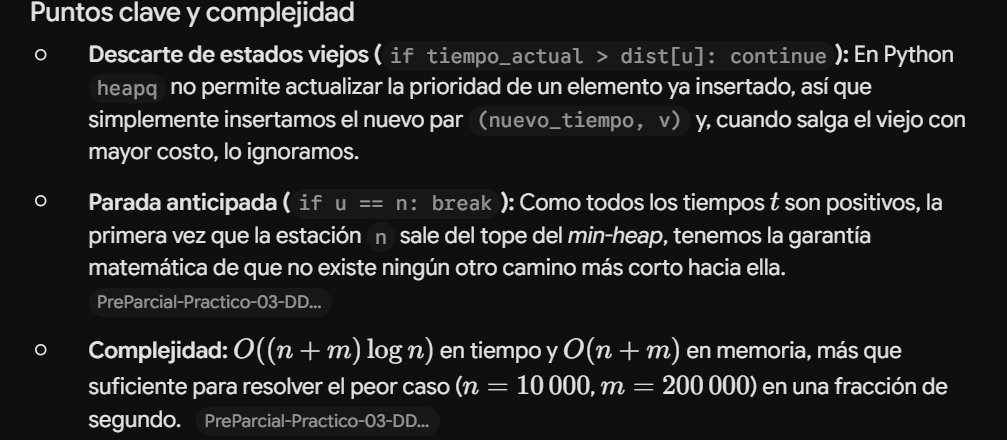



## Codigo Interactivo


In [ ]:
import heapq

def dijkstra_interactivo(n, grafo, inicio, destino):
    dist = [float('inf')] * (n + 1)
    padre = [-1] * (n + 1)
    dist[inicio] = 0
    cola = [(0, inicio)]  # (tiempo_acumulado, estacion_actual)

    while cola:
        tiempo_actual, u = heapq.heappop(cola)

        if tiempo_actual > dist[u]:
            continue

        if u == destino:
            break

        for v, peso in grafo[u]:
            nuevo_tiempo = tiempo_actual + peso
            if nuevo_tiempo < dist[v]:
                dist[v] = nuevo_tiempo
                padre[v] = u
                heapq.heappush(cola, (nuevo_tiempo, v))

    if dist[destino] == float('inf'):
        return None, []

    # Reconstruir la ruta desde destino hasta inicio
    ruta = []
    actual = destino
    while actual != -1:
        ruta.append(actual)
        actual = padre[actual]
    ruta.reverse()

    return dist[destino], ruta

def main():
    n = int(input("Ingrese el número de estaciones (n): "))
    while n < 2:
        n = int(input("Debe haber al menos 2 estaciones. Ingrese n: "))

    grafo = [[] for _ in range(n + 1)]
    menu = True

    while menu:
        print("\n--- ROBOT DE MANTENIMIENTO (DIJKSTRA) ---")
        print("1. Agregar corredor bidireccional (u v t)")
        print("2. Calcular ruta mínima de 1 a n")
        print("3. Reiniciar red de corredores")
        print("4. Salir")

        opcion = input("Seleccione una opción: ")

        if opcion == "1":
            u = int(input("Estación origen (u): "))
            v = int(input("Estación destino (v): "))
            t = int(input("Tiempo de recorrido (t): "))
            if 1 <= u <= n and 1 <= v <= n and t >= 1:
                grafo[u].append((v, t))
                grafo[v].append((u, t))
                print(f"Corredor agregado: {u} <-> {v} (tiempo: {t})")
            else:
                print(f"Error: Estaciones deben estar entre 1 y {n}, y tiempo >= 1.")

        elif opcion == "2":
            tiempo_min, ruta = dijkstra_interactivo(n, grafo, 1, n)
            if tiempo_min is None:
                print("Resultado: IMPOSIBLE (no existe ruta entre 1 y n).")
            else:
                ruta_str = " -> ".join(map(str, ruta))
                print(f"Menor tiempo total: {tiempo_min}")
                print(f"Ruta óptima: {ruta_str}")

        elif opcion == "3":
            grafo = [[] for _ in range(n + 1)]
            print("Corredores eliminados.")

        elif opcion == "4":
            print("Saliendo...")
            menu = False
        else:
            print("Opción inválida.")
main()

## Codigo Juez  

In [ ]:
import sys
import heapq

def main():
    datos = sys.stdin.read().split()
    if not datos:
        return

    n = int(datos[0])
    m = int(datos[1])

    grafo = [[] for _ in range(n + 1)]
    idx = 2
    for _ in range(m):
        u = int(datos[idx])
        v = int(datos[idx + 1])
        t = int(datos[idx + 2])
        idx += 3
        grafo[u].append((v, t))
        grafo[v].append((u, t))

    INF = float('inf')
    dist = [INF] * (n + 1)
    dist[1] = 0
    cola = [(0, 1)]

    while cola:
        tiempo_actual, u = heapq.heappop(cola)

        # Descartar entradas desactualizadas en la cola de prioridad
        if tiempo_actual > dist[u]:
            continue

        # Si ya extraemos el nodo destino, su distancia mínima es definitiva
        if u == n:
            break

        for v, peso in grafo[u]:
            nuevo_tiempo = tiempo_actual + peso
            if nuevo_tiempo < dist[v]:
                dist[v] = nuevo_tiempo
                heapq.heappush(cola, (nuevo_tiempo, v))

    if dist[n] == INF:
        print("IMPOSIBLE")
    else:
        print(dist[n])
main()

---
# Resumen para el parcial (hoja de trucos)

| Si el enunciado dice... | Piensa en... | Plantilla mental |
|---|---|---|
| "procesar primero el de mayor/menor prioridad", "sin reordenar todo" | **Heap** (`heapq`) | `(-prioridad, orden_llegada, dato)` |
| "consultar rápido por código/nombre", "esperadamente constante" | **Hash** (`dict`, `set`) | `d.get(k, 0)` + contadores actualizados en transiciones 0↔1 |
| "unir grupos", "¿están en la misma red?", "tamaño del grupo" | **Union-Find** | `find` con compresión + unión por tamaño; si `ra==rb` no hagas nada |
| "conectar todos con costo mínimo", "sin ciclos" | **MST** (Prim / Kruskal) | Grafo completo → Prim $O(n^2)$; aristas dadas → Kruskal + DSU |
| "menor tiempo/costo de A a B", pesos ≥ 0 | **Dijkstra** | heap `(dist, nodo)`, ignorar entradas obsoletas, grafo bidireccional → agrega ambas direcciones |
| pesos todos iguales (o sin peso) | **BFS** | cola `deque` |

### Errores frecuentes que cuestan puntos
1. **Heap:** olvidar que `heapq` es *min-heap*, o desempatar por nombre en vez de por llegada.
2. **Hash:** recalcular `TIPOS_ACTIVOS` recorriendo todo el diccionario.
3. **DSU:** no verificar `ra == rb` antes de unir (duplica tamaños); `find` recursivo en Python → `RecursionError`.
4. **MST:** confundirlo con "vecino más cercano"; olvidar que con $n=1$ la respuesta es 0.
5. **Dijkstra:** olvidar la arista en sentido contrario; usar `int` de 32 bits en C++/Java; no imprimir `IMPOSIBLE`.
6. **Entrada/Salida:** usar `input()` con 200 000 líneas (lento) → usa `sys.stdin.buffer.read().split()` e imprime con un solo `write`.

### Para practicar (sin mirar la solución)
- **A:** ¿Y si en empate debiera salir el que llegó **después**? → cambia `orden` por `-orden`.
- **B:** Agrega `MAS_PRESTADO` (modelo con más unidades). Pista: heap con entradas obsoletas, igual que Dijkstra.
- **C:** Agrega `NUM_REDES` (cuántas redes hay). Pista: empieza en `n` y resta 1 en cada unión efectiva.
- **D:** ¿Cuál es el cable **más largo** usado en el MST? → guarda el máximo de `dist[u]` en Prim.
- **E:** Imprime también la **ruta**. Pista: guarda `previo[v] = u` al relajar y reconstruye desde `n`.
